# Домашнее задание 9.3 — Почему массу нельзя всегда диагонализовать? (🟡)

Рассматриваю локальный треугольник $T=\{x\ge0,\ y\ge0,\ x+y\le1\}$ с единичной плотностью и площадью $1/2$. Добавляю к квадратичному элементу центральный узел и внутреннюю функцию, исследую узловые массы, точность квадратуры и матрицу жёсткости.

Ноутбук выполняется самостоятельно. Все необходимые функции стандартного элемента определены ниже. Порядок узлов — вершины 1, 2, 3, середины рёбер 12, 23, 31 и центр. Интегралы вычисляю точно, численные спектральные проверки провожу с абсолютным допуском $10^{-10}$.

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from IPython.display import display

TOL = 1e-10
x, y = sp.symbols("x y", real=True)
lam = [1-x-y, x, y]
nodes1 = [(0, 0), (1, 0), (0, 1)]
nodes2 = nodes1 + [(sp.Rational(1,2), 0), (sp.Rational(1,2), sp.Rational(1,2)), (0, sp.Rational(1,2))]
nodes7 = nodes2 + [(sp.Rational(1,3), sp.Rational(1,3))]
labels = ['1', '2', '3', '12', '23', '31', 'c']
P1 = lam
P2 = [l*(2*l-1) for l in lam] + [4*lam[0]*lam[1], 4*lam[1]*lam[2], 4*lam[2]*lam[0]]
def integ(f):
    return sp.integrate(sp.integrate(sp.expand(f), (y, 0, 1-x)), (x, 0, 1))
def at(f, p):
    return sp.expand(f).subs({x:p[0], y:p[1]})
def gram(fs):
    return sp.Matrix([[integ(a*b) for b in fs] for a in fs])
def as_float(A):
    return np.array(A, dtype=float)
def show_matrix(name, A):
    print(name)
    display(A)


In [2]:
grid = np.linspace(0, 1, 101)
xy = np.array([(a, b) for a in grid for b in grid if a+b <= 1+1e-12])
tri = mtri.Triangulation(xy[:,0], xy[:,1])
def values(f):
    return np.asarray(sp.lambdify((x,y), f, 'numpy')(xy[:,0],xy[:,1]))
def maps(fs, names, ncols, limits):
    rows = (len(fs)+ncols-1)//ncols
    fig, axes = plt.subplots(rows, ncols, figsize=(3.8*ncols, 3.4*rows), squeeze=False, constrained_layout=True)
    for ax, f, name in zip(axes.flat, fs, names):
        im = ax.tricontourf(tri, values(f), levels=np.linspace(*limits, 31), cmap='coolwarm', extend='both')
        ax.plot([0,1,0,0], [0,0,1,0], 'k-', lw=.7)
        ax.set(title=name, xlabel='x', ylabel='y', aspect='equal')
    for ax in list(axes.flat)[len(fs):]: ax.set_visible(False)
    fig.colorbar(im, ax=list(axes.flat), label='Значение функции', shrink=.8)
    plt.show()

## 1. Обогащение внутренней функцией

Пусть $b=27\lambda_1\lambda_2\lambda_3$. Для старых узлов $\widetilde\varphi_i=\varphi_i-\varphi_i(1/3,1/3)b$, а $\widetilde\varphi_7=b$. Пузырь равен нулю на каждом ребре, поэтому следы первых шести функций не меняются.

В центре старые вершинные функции равны $-1/9$, а рёберные — $4/9$. Поэтому новые функции имеют явный вид

$$
\widetilde\varphi_i=\lambda_i(2\lambda_i-1)+b/9,\qquad
\widetilde\varphi_{ij}=4\lambda_i\lambda_j-4b/9,\qquad
\widetilde\varphi_c=b.
$$

Их сумма равна единице, поскольку суммарная добавка к первым шести функциям равна $-b$, а седьмая функция добавляет $b$.


Семь функций формы:
1: -(x + y - 1)*(3*x*y - 2*x - 2*y + 1)
2: -x*(3*x*y - 2*x + 3*y**2 - 3*y + 1)
3: -y*(3*x**2 + 3*x*y - 3*x - 2*y + 1)
12: 4*x*(3*y - 1)*(x + y - 1)
23: 4*x*y*(3*x + 3*y - 2)
31: 4*y*(3*x - 1)*(x + y - 1)
c: -27*x*y*(x + y - 1)
Нодальность, единица, воспроизведение P2 и все три следа: точные проверки пройдены.
Узловые массы


Matrix([
[1/40],
[1/40],
[1/40],
[1/15],
[1/15],
[1/15],
[9/40]])

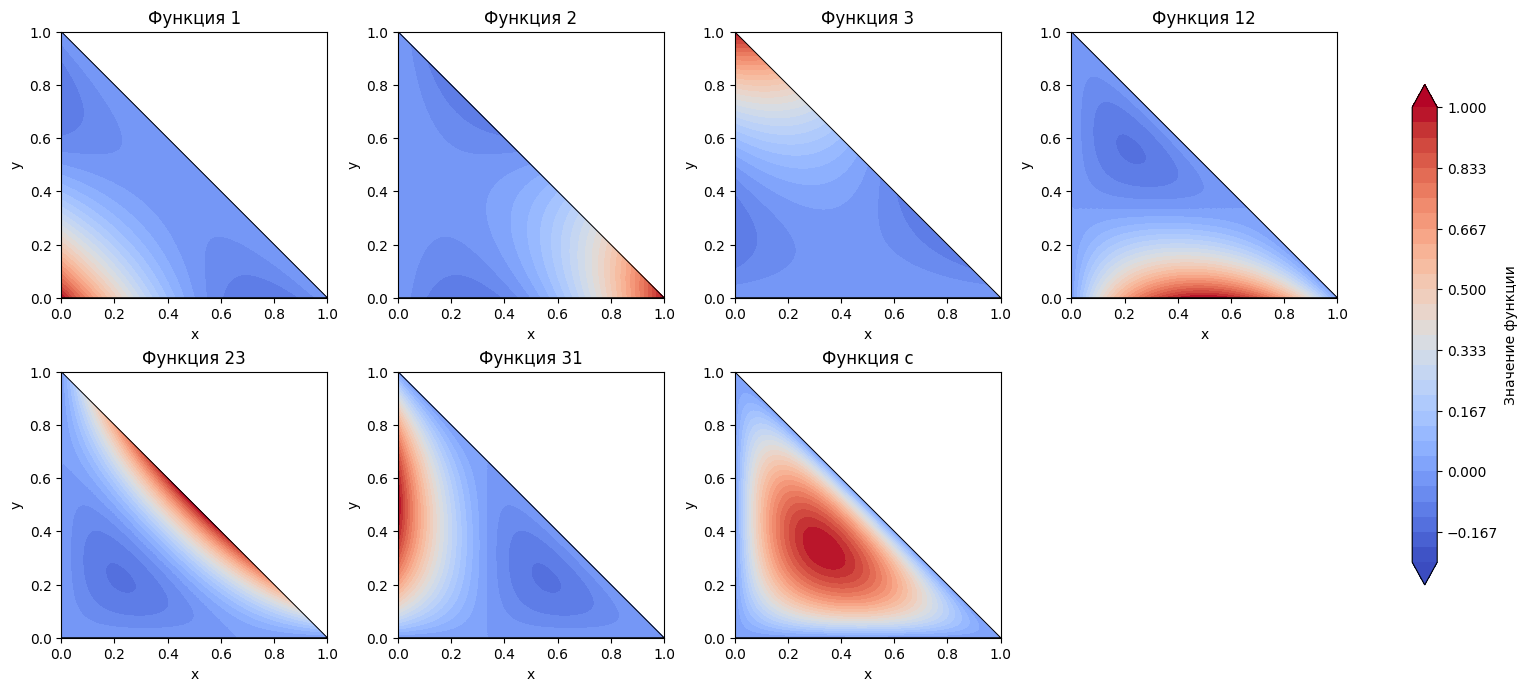

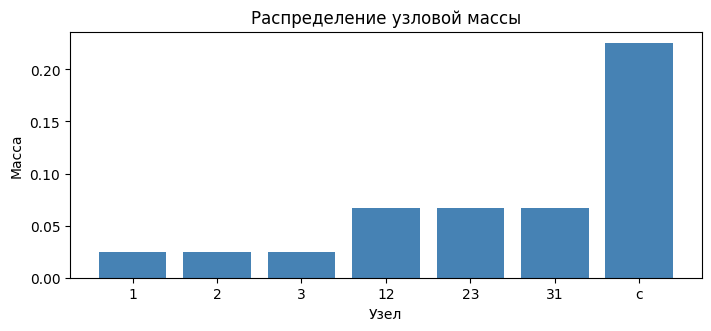

In [3]:
bubble = 27*lam[0]*lam[1]*lam[2]
P7 = [sp.expand(f-at(f,nodes7[-1])*bubble) for f in P2] + [sp.expand(bubble)]
print('Семь функций формы:')
for label, f in zip(labels, P7):
    print(f'{label}: {sp.factor(f)}')
nodal7 = sp.Matrix([[at(f,p) for f in P7] for p in nodes7])
assert nodal7 == sp.eye(7)
assert sp.expand(sum(P7)-1) == 0
monomials = [x**a*y**b for degree in range(3) for a in range(degree+1) for b in [degree-a]]
assert all(sp.expand(sum(at(p,pt)*f for pt,f in zip(nodes7,P7))-p) == 0 for p in monomials)
# Рёбра: y=0, x=0 и y=1-x.
for f, old in zip(P7, P2+[sp.Integer(0)]):
    assert all(sp.expand((f-old).subs(sub)) == 0 for sub in [{y:0}, {x:0}, {y:1-x}])
print('Нодальность, единица, воспроизведение P2 и все три следа: точные проверки пройдены.')
m7 = sp.Matrix([integ(f) for f in P7])
assert all(v > 0 for v in m7) and sum(m7) == sp.Rational(1,2)
show_matrix('Узловые массы', m7)
maps(P7, ['Функция '+s for s in labels], 4, (-.25, 1))
fig, ax = plt.subplots(figsize=(7,3.2), constrained_layout=True)
ax.bar(labels, np.array(m7, dtype=float).ravel(), color='steelblue')
ax.set(xlabel='Узел', ylabel='Масса', title='Распределение узловой массы')
plt.show()

## 2. Узловая квадратура

$Q(f)=\sum_i m_i f(x_i,y_i)$. Проверяю каждый моном до степени четыре; ошибка в таблице равна $Q(f)-\int_T f$. Степень точности — наибольшая степень, для которой все мономы интегрируются точно.

In [4]:
def quad(f):
    return sp.simplify(sum(m*at(f,p) for m,p in zip(m7,nodes7)))
records=[]
for degree in range(5):
    for a in range(degree+1):
        b=degree-a
        f=x**a*y**b
        exact=integ(f); q=quad(f); error=sp.simplify(q-exact)
        records.append((degree, a, b, str(exact), str(q), str(error), float(abs(error))))
table=pd.DataFrame(records, columns=['степень','a','b','интеграл','Q','Q − интеграл','|ошибка|'])
display(table)
summary=table.groupby('степень')['|ошибка|'].max()
print('Максимальная абсолютная ошибка по степени:')
display(summary)
precision = next(d-1 for d in range(5) if any(r[0]==d and r[5]!='0' for r in records))
assert precision == 3
print('Степень точности:', precision)

,степень,a,b,интеграл,Q,Q − интеграл,|ошибка|
0,0,0,0,1/2,1/2,0,0.000000
1,1,0,1,1/6,1/6,0,0.000000
2,1,1,0,1/6,1/6,0,0.000000
3,2,0,2,1/12,1/12,0,0.000000
4,2,1,1,1/24,1/24,0,0.000000
5,2,2,0,1/12,1/12,0,0.000000
6,3,0,3,1/20,1/20,0,0.000000
7,3,1,2,1/60,1/60,0,0.000000
8,3,2,1,1/60,1/60,0,0.000000
9,3,3,0,1/20,1/20,0,0.000000


Максимальная абсолютная ошибка по степени:


степень
0    0.000000
1    0.000000
2    0.000000
3    0.000000
4    0.002778
Name: |ошибка|, dtype: float64

Степень точности: 3


## 3. Точная и квадратурная жёсткость

$K_{ij}=\int_T\nabla\widetilde\varphi_i\cdot\nabla\widetilde\varphi_j$; $K_Q$ получена применением той же узловой квадратуры к каждому скалярному произведению градиентов. Проверка ядра проводится для точной матрицы с допуском $10^{-10}$.

In [5]:
grad = [(sp.diff(f,x), sp.diff(f,y)) for f in P7]
integrands = [[sp.expand(a[0]*b[0]+a[1]*b[1]) for b in grad] for a in grad]
K = sp.Matrix([[integ(f) for f in row] for row in integrands])
Kq = sp.Matrix([[quad(f) for f in row] for row in integrands])
D = Kq-K
show_matrix('Точная матрица K', K)
show_matrix('Узловая квадратура K_Q', Kq)
show_matrix('Разность K_Q − K', D)
eigs = np.linalg.eigvalsh(as_float(K))
assert K == K.T and K*sp.ones(7,1) == sp.zeros(7,1)
assert np.sum(np.abs(eigs)<TOL) == 1 and np.all(eigs[1:] > TOL)
print('eig(K) =', np.round(eigs, 10))
print('Размерность ядра:', np.sum(np.abs(eigs)<TOL))
print('Максимальная абсолютная разность матриц:', float(max(abs(v) for v in D)))
a = sp.Matrix([sp.Rational(1,9)]*3 + [-sp.Rational(4,9)]*3 + [1])
assert D == sp.Rational(81,20)*a*a.T
assert Kq*sp.ones(7,1) == sp.zeros(7,1)
assert Kq.rank() == 6
print('Разность имеет ранг один; у K_Q также одна постоянная нулевая мода.')


Точная матрица K


Matrix([
[ 7/10, -1/30, -1/30, -1/15,   2/5, -1/15, -9/10],
[-1/30,   2/5, -1/10, -7/15,     0,   1/5,     0],
[-1/30, -1/10,   2/5,   1/5,     0, -7/15,     0],
[-1/15, -7/15,   1/5,   8/3, -8/15,     0,  -9/5],
[  2/5,     0,     0, -8/15, 64/15, -8/15, -18/5],
[-1/15,   1/5, -7/15,     0, -8/15,   8/3,  -9/5],
[-9/10,     0,     0,  -9/5, -18/5,  -9/5, 81/10]])

Узловая квадратура K_Q


Matrix([
[  3/4,  1/60,  1/60, -4/15,   1/5, -4/15,  -9/20],
[ 1/60,  9/20, -1/20,  -2/3,  -1/5,     0,   9/20],
[ 1/60, -1/20,  9/20,     0,  -1/5,  -2/3,   9/20],
[-4/15,  -2/3,     0, 52/15,  4/15,   4/5,  -18/5],
[  1/5,  -1/5,  -1/5,  4/15, 76/15,  4/15,  -27/5],
[-4/15,     0,  -2/3,   4/5,  4/15, 52/15,  -18/5],
[-9/20,  9/20,  9/20, -18/5, -27/5, -18/5, 243/20]])

Разность K_Q − K


Matrix([
[1/20, 1/20, 1/20, -1/5, -1/5, -1/5,  9/20],
[1/20, 1/20, 1/20, -1/5, -1/5, -1/5,  9/20],
[1/20, 1/20, 1/20, -1/5, -1/5, -1/5,  9/20],
[-1/5, -1/5, -1/5,  4/5,  4/5,  4/5,  -9/5],
[-1/5, -1/5, -1/5,  4/5,  4/5,  4/5,  -9/5],
[-1/5, -1/5, -1/5,  4/5,  4/5,  4/5,  -9/5],
[9/20, 9/20, 9/20, -9/5, -9/5, -9/5, 81/20]])

eig(K) = [-0.          0.31130521  0.40207785  0.75657398  2.85536146  4.10075327
 10.77392824]
Размерность ядра: 1
Максимальная абсолютная разность матриц: 4.05
Разность имеет ранг один; у K_Q также одна постоянная нулевая мода.


Точная жёсткость имеет единственную нулевую моду $\mathbf1$: постоянная функция имеет нулевой градиент, все остальные моды дают положительную энергию. Квадратура точна только до степени три, а градиенты обогащённых функций имеют степень два, поэтому их произведения могут иметь степень четыре. Положительные узловые веса обеспечивают положительную диагональную массу при узловой квадратуре, но не точность этих интегралов жёсткости.

Вычисленные массы равны $1/40$ в каждой вершине, $1/15$ в каждой середине ребра и $9/40$ в центре. Их сумма равна $1/2$. Для примера, $Q(x^4)=13/360$, тогда как $\int_Tx^4=1/30$, поэтому ошибка составляет $1/360$.

Разность жёсткостей можно записать точно через коэффициенты пузыря

$$
K_Q-K=\frac{81}{20}aa^T,\qquad
a=(1/9,1/9,1/9,-4/9,-4/9,-4/9,1)^T.
$$

Перекрёстные произведения градиентов квадратичной части и пузыря имеют степень не выше трёх и интегрируются точно. Ошибка возникает в произведении градиента пузыря на себя, имеющем степень четыре. Разность имеет ранг один и неотрицательную квадратичную форму. При этом обе матрицы сохраняют единственную постоянную нулевую моду.
